# Directed Return Networks

Daily cryptocurrency lead-lag research using level-two signatures. The study covers a retrospectively selected 57-asset universe, with portfolio returns from 21 August 2019 to 5 November 2023. It is a historical research sample, not an independent holdout or live track record.

The main method ranks assets globally. Additional exploratory comparisons are kept in `experiments.ipynb`.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT=Path.cwd()
if not (ROOT/'config.json').exists():
    ROOT=ROOT.parent
A=ROOT/'artifacts'
scores=pd.read_csv(A/'scores.csv').query("mode == 'global'")
display(scores.query('cost_bps == 0 and extra_delay == 0')[['days','sharpe','sharpe_rf_2pct','max_drawdown']].round(4))

,days,sharpe,sharpe_rf_2pct,max_drawdown
8,1538,1.4123,1.339,-0.2321


## Signal and portfolio

Standardize the latest 30 daily returns. For return path $z$, the antisymmetric level-two area is

$$A=\frac12\sum_t[(z_t-z_0)\Delta z_t^\top-\Delta z_t(z_t-z_0)^\top].$$

Row averages rank leaders and followers. The highest and lowest 20% form the two groups. The sign of the leaders' latest average return determines the direction of a follower-minus-universe portfolio. Hedge membership is based on instruments observable at decision time.

The NumPy calculation is checked against an independent signature recursion. Target weights are dollar neutral; that does not imply zero market beta. Gross exposure is generally about 1.6 because the follower and universe baskets overlap.

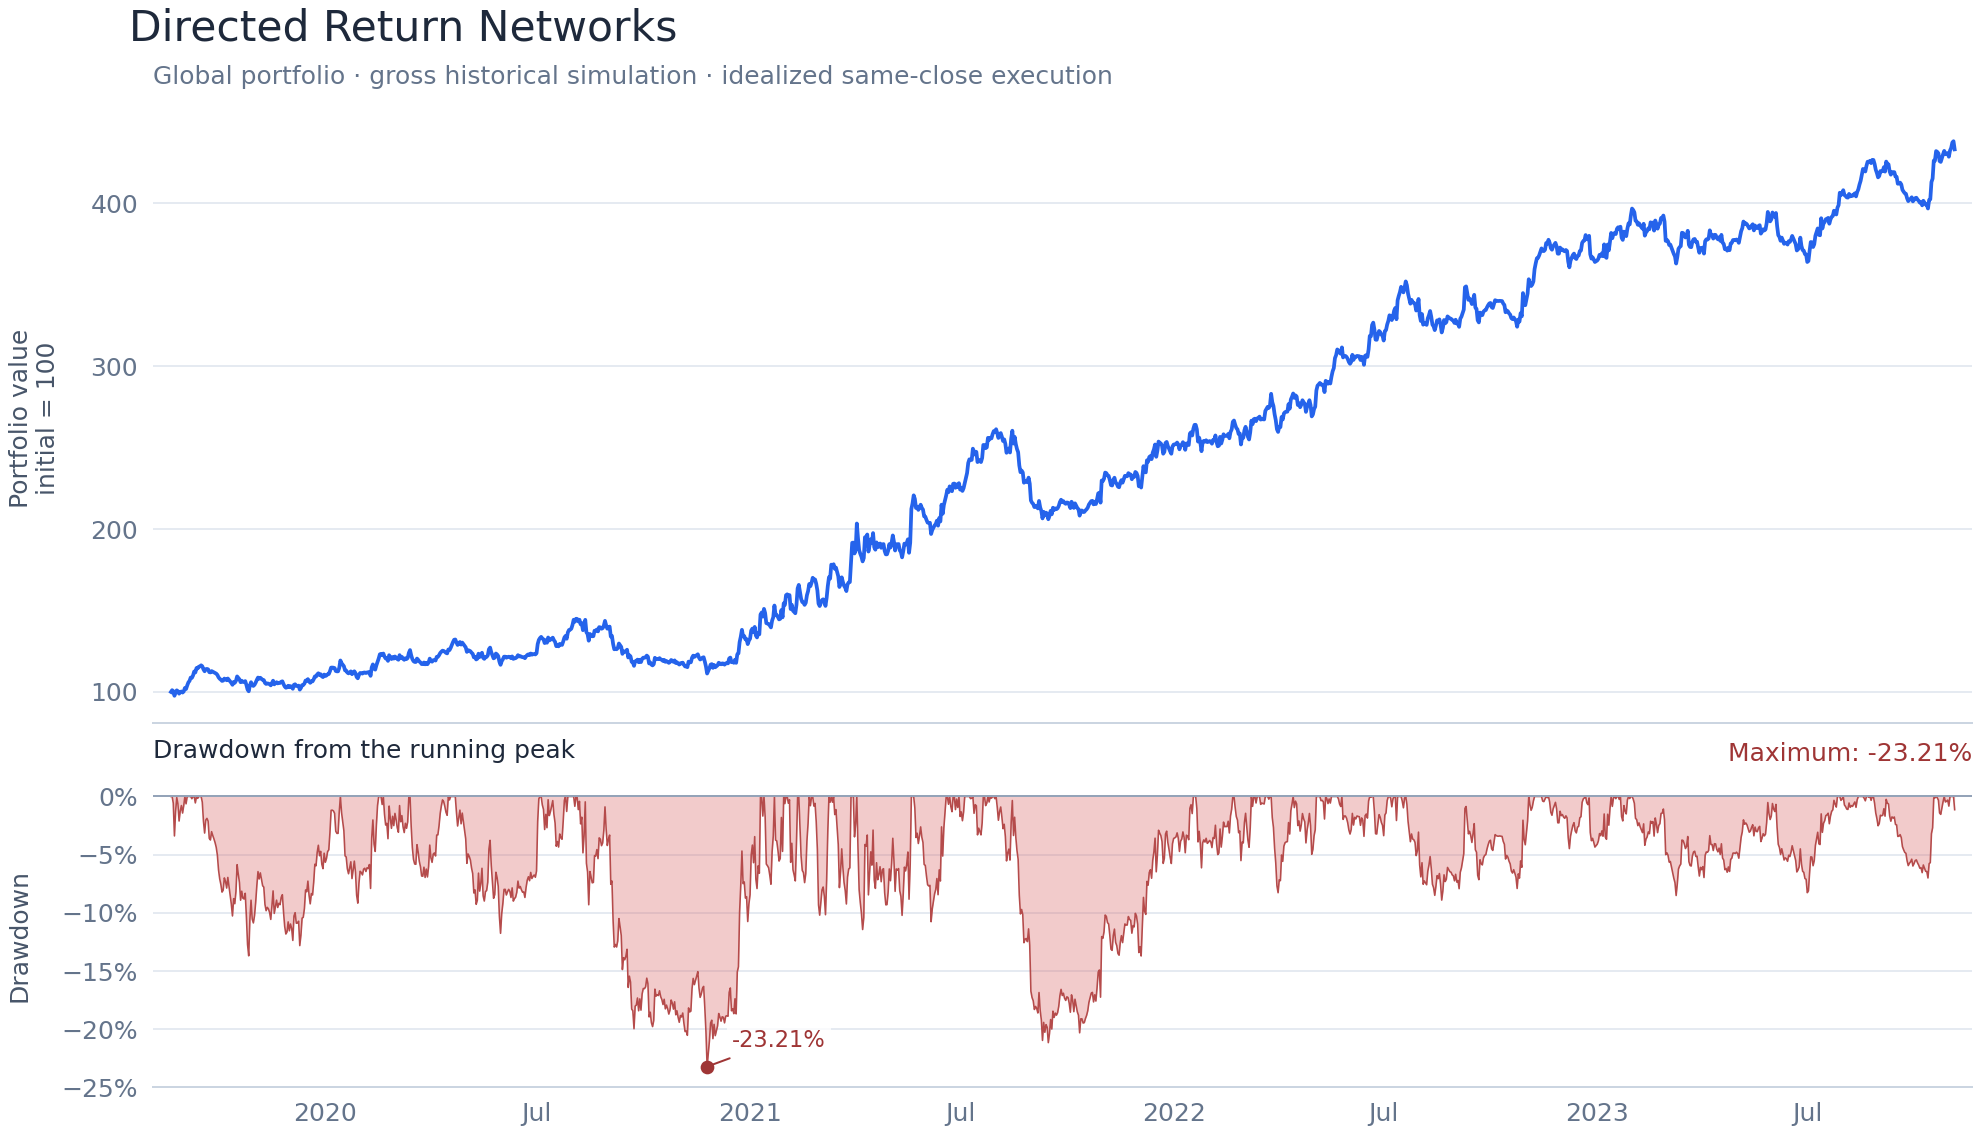

In [2]:
display(Image(filename=str(A/'directed-return-networks.png')))

## Costs and execution

The headline gross Sharpe is 1.41 with zero cash rate, or 1.34 under a 2% annual cash-rate assumption. These omit transaction, funding and borrowing costs. Zero-delay assumes execution at the same closing price used to form the signal.

At 5 bps on each traded dollar, global Sharpe is 0.14. An additional day of delay gives a negative gross Sharpe. The portfolio changes positions frequently: average one-way turnover is about 190% of NAV per day.

The ledger includes entry, rebalancing and final liquidation. Funding and borrow availability remain unmodeled even in fee scenarios. Missing marks are carried forward for valuation, not treated as proof of executable fills.

In [3]:
display(scores[['extra_delay','cost_bps','sharpe','max_drawdown','mean_daily_turnover']].round(4))

,extra_delay,cost_bps,sharpe,max_drawdown,mean_daily_turnover
8,0,0,1.4123,-0.2321,1.9017
9,0,5,0.1379,-0.3723,1.9004
10,0,10,-1.1422,-0.8020,1.8990
11,0,20,-3.6842,-0.9885,1.8963
12,1,0,-0.0954,-0.4710,1.9014
13,1,5,-1.3587,-0.8302,1.9000
14,1,10,-2.6096,-0.9598,1.8987
15,1,20,-5.0428,-0.9978,1.8960


## Historical subperiods and uncertainty

These are descriptive slices of the existing historical sample, not fresh holdouts. Bootstrap intervals use 2,000 common 30-day block resamples and do not account for the history of strategy selection.

In [4]:
display(pd.read_csv(A/'subperiods.csv').query("mode == 'global'")[['period','days','sharpe','max_drawdown']].round(4))
display(pd.read_csv(A/'uncertainty.csv').query("mode == 'global'").round(4))
run=json.loads((A/'run.json').read_text())
print('Snapshot SHA-256:',run['price_sha256'])

,period,days,sharpe,max_drawdown
2,2019-2021,864,1.3527,-0.2321
3,2022-2023,674,1.7164,-0.0890


,mode,lower_95,upper_95,block_days,repetitions
1,global,0.6297,2.1623,30,2000


Snapshot SHA-256: e919b8d5c3cd712f1ff006aec5c50cc52fb4614b87041c2788f5285215da5b0b


## Reproduce

Run `python -m leadlag.research` from the repository root. The full runner also computes the exploratory comparisons archived in `experiments.ipynb`.

Implementation/data reference: [ARahimiQuant/lead-lag-portfolios](https://github.com/ARahimiQuant/lead-lag-portfolios), pinned in `config.json`, with the MIT notice retained in `LICENSE`. Method references: [Bennett, Cucuringu and Reinert](https://arxiv.org/abs/2201.08283); [Chevyrev and Kormilitzin](https://arxiv.org/abs/1603.03788).

The historical gross signal does not establish deployable profits after costs or execution latency.